In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy
from sklearn.metrics import mean_squared_error, root_mean_squared_error,mean_absolute_error,r2_score

df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/Ice_cream selling data.csv")

df.head(5)

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


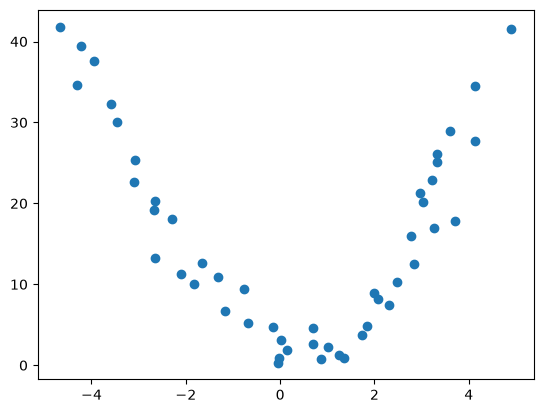

In [4]:
import matplotlib.pyplot as plt

plt.scatter(df["Temperature (°C)"],df["Ice Cream Sales (units)"])

In [5]:
print(df.corr())

                         Temperature (°C)  Ice Cream Sales (units)
Temperature (°C)                 1.000000                -0.175184
Ice Cream Sales (units)         -0.175184                 1.000000


Note:
-> Data is non linear because it is having close to zero correlation.
-> SO we cant use the linear regression here
-> But just for experimentation purpose we will use it.

In [6]:
# x = df[["Temperature (°C)","Ice Cream Sales (units)"]]
x = df[["Temperature (°C)"]]
y = df["Ice Cream Sales (units)"]

In [7]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)

In [8]:
model_lr = LinearRegression()

In [9]:
model_lr.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-1.15]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature (°C)']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [10]:
model_lr.intercept_

np.float64(17.139213127718417)

In [11]:
# Slope

model_lr.coef_

array([-1.14658686])

# Note:

-> intercept_ and coef_ are variables defined inside the fit() method. so without calling fit() we cannot access these variables

In [12]:
'''
slopes are the weights of the input features/columns

what is weights

-> it tells the importance of the features (inputs).

-> based on the weights, models decides the importance of features (inputs).

'''

'\nslopes are the weights of the input features/columns\n\nwhat is weights\n\n-> it tells the importance of the features (inputs).\n\n-> based on the weights, models decides the importance of features (inputs).\n\n'

# Model Evaluation

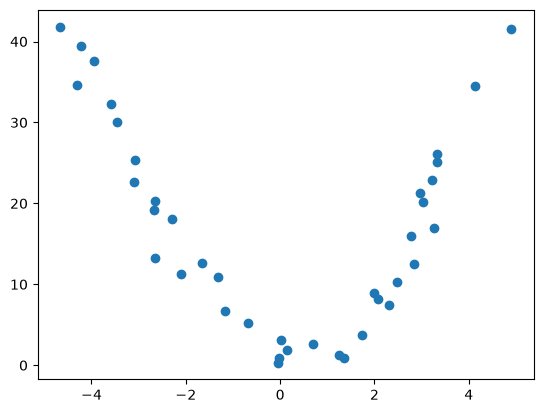

In [13]:
plt.scatter(x_train,y_train)

In [14]:
'''
predict()

-> it is a method defined under the class of the model (LinearRegression)
-> syntax is :
    model.predict(x)
-> usage:
    y_train_predicted = model_lr.predict(x_train)

'''

'\npredict()\n\n-> it is a method defined under the class of the model (LinearRegression)\n-> syntax is :\n    model.predict(x)\n-> usage:\n    y_train_predicted = model_lr.predict(x_train)\n\n'

In [15]:
y_train_predicted = model_lr.predict(x_train)


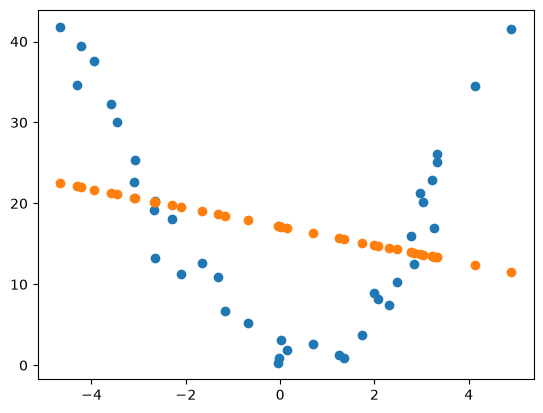

In [16]:
plt.scatter(x_train,y_train)    # actual input vs actual output

plt.scatter(x_train,y_train_predicted)    # actual input vs predicted output

# Conclusion

-> Here we can see that the the models actual and predicted output differ and not same .

-> So conclusion is that model is not able to capture the patterns .

-> Reason: Data is non linear and linear regression can capture only the linear data.

-> In the begining only by the correlation matrix we conformed it , but now we can see it clearly with proof that the model didnt learn the pattern.

In [17]:
'''
why we are comparing this ?

    1) plt.scatter(x_train,y_train)    # actual input vs actual output

    2) plt.scatter(x_train,y_train_predicted)    # actual input vs predicted output

Answer:
From this comparison between actual pattern and predicted pattern ,
we can conclude how well the model captures the pattern during model training.
'''

'\nwhy we are comparing this ?\n\n    1) plt.scatter(x_train,y_train)    # actual input vs actual output\n\n    2) plt.scatter(x_train,y_train_predicted)    # actual input vs predicted output\n\nAnswer:\nFrom this comparison between actual pattern and predicted pattern ,\nwe can conclude how well the model captures the pattern during model training.\n'

# Model Testing

predicting on the unseen data

In [18]:


y_test_predicted = model_lr.predict(x_test)

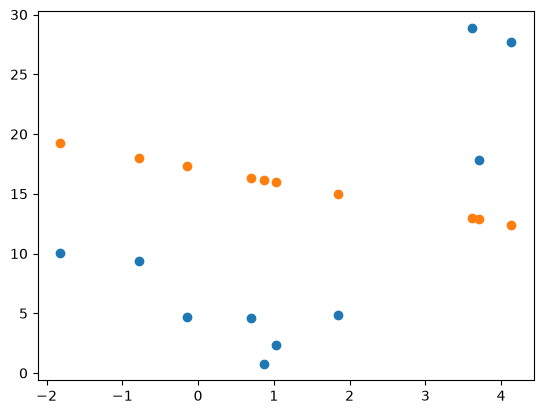

In [19]:
plt.scatter(x_test,y_test)    # actual input vs actual output

plt.scatter(x_test,y_test_predicted)    # actual input vs predicted output



# Conclusion

-> The model couldnt learn the patterns in the data, hence it failed to perform in the test data as well.

-> Therefore we can conclude that we cannot use linear regression for this purticular dataset.

In [20]:
train_data = pd.DataFrame({
    'X_train': x_train["Temperature (°C)"],
    'Y_train' : y_train,
    'Y_train_predicted': y_train_predicted
    })


In [21]:
train_data['Error'] = train_data['Y_train']- train_data['Y_train_predicted']

In [22]:
print(train_data)

     X_train    Y_train  Y_train_predicted      Error
12 -2.111870  11.218294          19.560655  -8.342361
4  -3.578554  32.284531          21.242336  11.042195
34  2.318591   7.412094          14.480747  -7.068653
8  -2.672461  19.226970          20.203422  -0.976452
3  -3.949661  37.539845          21.667843  15.872002
6  -3.108440  22.635401          20.703310   1.932092
40  3.211366  22.839406          13.457103   9.382303
41  3.270044  16.983279          13.389824   3.593455
46  4.130868  34.530743          12.402814  22.127929
15 -1.326379  10.957731          18.660022  -7.702291
9  -2.652287  20.279679          20.180290   0.099389
16 -1.173123   6.689123          18.484301 -11.795178
24  0.688781   2.576782          16.349466 -13.772684
33  2.075101   8.170735          14.759930  -6.589195
30  1.740000   3.782570          15.144152 -11.361582
0  -4.662263  41.842986          22.484902  19.358084
43  3.335932  26.104740          13.314277  12.790464
32  1.999310   8.943823     

# Regression Evaluation metrics

1. Mean Squared Error (MSE)
2. Root Mean Squared Error (RMSE)
3. Mean Absolute Error (MAE)
4. r^2 score

We first checks the r2 score because only this metric gives us the indication of overall model performance.

In [23]:
# 4. r2 score

train_r2_score =r2_score(y_train,y_train_predicted)

test_r2_score= r2_score(y_test,y_test_predicted)


print(train_r2_score, test_r2_score)

0.06579063815950037 -0.5751270190188227


As per the results, we can say that :

Based on the low r2 score on train data we can say that the model is not being able to capture data patterns properly
because the data is non linear

Based on the low r2 score (negative is even lower) we can say that this model is not ready for the future predictions.

In [24]:
# 2. Root Mean Squared Error (RMSE)

train_rmse =root_mean_squared_error(y_train,y_train_predicted)

test_rmse = root_mean_squared_error(y_test,y_test_predicted)


print(train_rmse, test_rmse)

11.972117646423854 12.219913714640208


In [25]:
# 3. Mean Absolute Error (MAE)

train_mae =mean_absolute_error(y_train,y_train_predicted)

test_mae = mean_absolute_error(y_test,y_test_predicted)


print(train_mae, test_mae)

10.136398159361041 11.752026695440602


In [26]:
# Error percentage based on the MAE .

# To check if an mae value is high or not we should use it to calculate the error percentage
#  error percentage based on mae equation is : (average(y_train) / mae )* 100

avg_of_y_train = sum(y_train)/len(y_train)

print("Average of Y train: ",avg_of_y_train)

error_percentage_based_on_mae = (avg_of_y_train/train_mae)*100

print("Error percentage based on mae: ",error_percentage_based_on_mae)

Average of Y train:  17.13432359205404
Error percentage based on mae:  169.03759424870623


Note:

1. In this case eventhough the rmse and mae values are close , the model is underperforming
2. So we should always check the r2_score first and give it highest priority for conclusions regarding model performance
3. Then check mae and rmse values and check if they have huge differences.
4. If they have huge difference that means model didnt understood outlier patterns well
5. if no such huge difference like in this case then that means model understoods the outlier patterns well.
6. Then check on error percentage calculated from the mae value and see how much error percentage is for the model.
7. Give the least importance to the mse metric as it is not actual but a sqaured error representation.


In [27]:
# 1. Mean Squared Error (MSE)

train_mse = mean_squared_error(y_train,y_train_predicted)

test_mse = mean_squared_error(y_test,y_test_predicted)


print(train_mse, test_mse)

# Since the error is squared , it does not represent the actual error value. 
# so it is mostly used in model training (in regularization) and it is rarely used in model evaluation.
# Because what it represents is the not the actual error, but the sqaured error.
# this squaring operation will make the actual error way bigger. so it can be used in the model training to catch even small errors and to make the model generalize.

143.33160093981343 149.32629119325185
